# CIC-IDS2017 — Exploratory Data Analysis
**Anomaly Flow Detector V2 · Slice 1.5**

Required by SPEC.md §5.0. Covers all 7 mandated analyses:
1. Dataset inventory & fixture detection
2. Label distribution by capture session
3. Label imbalance per split (train / val / test)
4. Feature drift across capture days
5. Benign-traffic seasonality: Fri-AM vs Mon–Thu
6. Correlation heatmap (pre- and post-pruning)
7. Feature variance ranking

> **If fewer than 8 CSV files are found, run `make dataset` from the project root first.**
> The analyses still execute on partial data with clearly marked caveats.


In [1]:
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 110

# ── Paths ────────────────────────────────────────────────────────────────
# Works when run from training/eda/ OR from project root
PROJECT_ROOT = Path(__file__).resolve().parents[2] if "__file__" in dir() else Path.cwd()
while not (PROJECT_ROOT / "SPEC.md").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data" / "CIC-IDS2017"
print(f"Project root : {PROJECT_ROOT}")
print(f"Dataset path : {DATA_DIR}")
print(f"Exists       : {DATA_DIR.exists()}")


Project root : /home/hhaniffa/dev/modules/CS7003NU-Advanced-AI-Technologies/dev/anomaly-flow-detector
Dataset path : /home/hhaniffa/dev/modules/CS7003NU-Advanced-AI-Technologies/dev/anomaly-flow-detector/data/CIC-IDS2017
Exists       : True


## 1 · Dataset Inventory

In [2]:
EXPECTED_FILES = [
    "Monday-WorkingHours.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-WorkingHours.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
]

found  = sorted(DATA_DIR.glob("*.csv")) if DATA_DIR.exists() else []
found_names = {f.name for f in found}
missing = [f for f in EXPECTED_FILES if f not in found_names]

print(f"Found  : {len(found)} / {len(EXPECTED_FILES)} expected files")
if missing:
    print("\nMISSING (run `make dataset` to download):")
    for m in missing:
        print(f"  ✗  {m}")

rows_by_file = {}
for f in found:
    n = duckdb.sql(f"SELECT COUNT(*) FROM read_csv_auto('{f}', header=true)").fetchone()[0]
    rows_by_file[f.name] = n

total_rows = sum(rows_by_file.values())
print(f"\nTotal rows across found files: {total_rows:,}")

IS_FIXTURE = total_rows < 10_000
if IS_FIXTURE:
    print("\n⚠️  FIXTURE DATA DETECTED (< 10 k rows).")
    print("   EDA runs but results are not meaningful for tuning — download real data first.")
else:
    print("\n✓  Real CIC-IDS2017 data detected.")

# Display per-file counts
inv = pd.DataFrame({"file": list(rows_by_file.keys()), "rows": list(rows_by_file.values())})
inv["split"] = inv["file"].apply(lambda f:
    "val"  if "Friday" in f and "Morning" in f else
    "test" if "Friday" in f else "train")
display(inv.sort_values("file").reset_index(drop=True))


Found  : 3 / 8 expected files

MISSING (run `make dataset` to download):
  ✗  Tuesday-WorkingHours.pcap_ISCX.csv
  ✗  Wednesday-WorkingHours.pcap_ISCX.csv
  ✗  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
  ✗  Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
  ✗  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv



Total rows across found files: 3,000

⚠️  FIXTURE DATA DETECTED (< 10 k rows).
   EDA runs but results are not meaningful for tuning — download real data first.


,file,rows,split
0,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,1000,test
1,Friday-WorkingHours-Morning.pcap_ISCX.csv,1000,val
2,Monday-WorkingHours.pcap_ISCX.csv,1000,train


## 2 · Label Distribution by Capture Session

Each row is one capture session (file). Colours show attack types.
Key expectation (ADR-02): Fri-PM contains **DDoS + PortScan only** — attack types
the classifier never sees during training → genuine novel-attack test set.


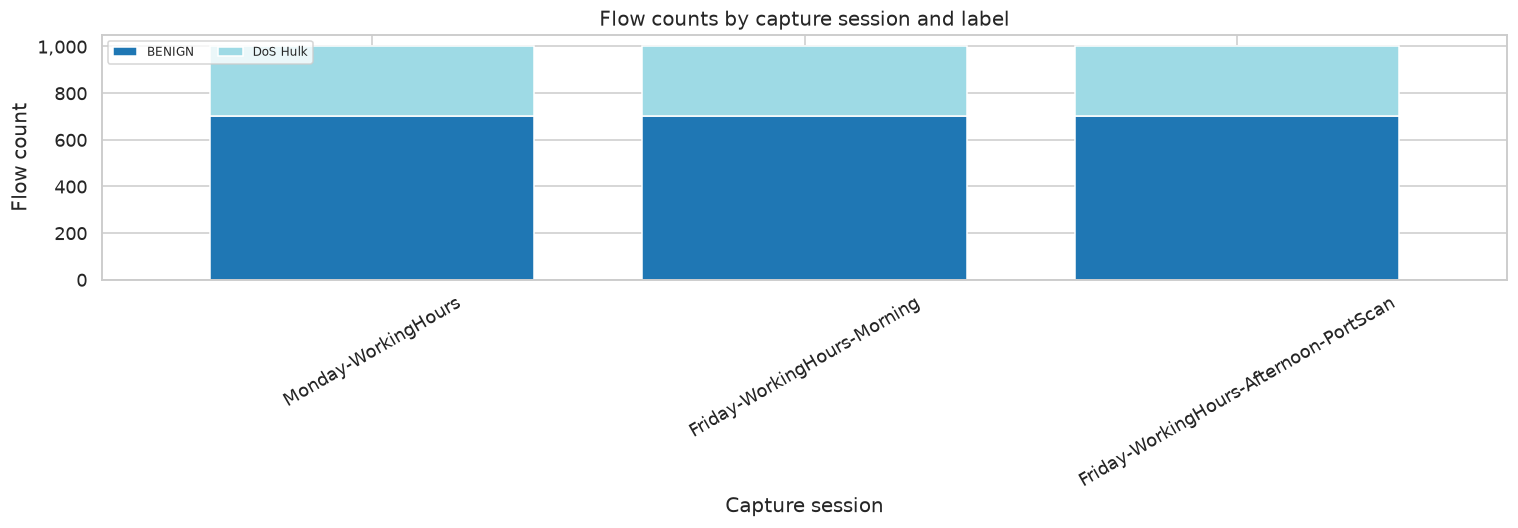


Attack types per session:
  Friday-WorkingHours-Afternoon-PortScan                   ['DoS Hulk']
  Friday-WorkingHours-Morning                              ['DoS Hulk']
  Monday-WorkingHours                                      ['DoS Hulk']


In [3]:
def load_labels(path: Path) -> pd.DataFrame:
    df = duckdb.sql(
        f"SELECT Label, COUNT(*) as n FROM read_csv_auto('{path}', header=true) GROUP BY Label"
    ).df()
    df["file"] = path.stem.replace(".pcap_ISCX", "")
    return df

label_dfs = [load_labels(f) for f in found]
if not label_dfs:
    print("No data found — run `make dataset`.")
else:
    ldf = pd.concat(label_dfs, ignore_index=True)

    # Pivot: files × labels
    pivot = ldf.pivot_table(index="file", columns="Label", values="n", fill_value=0)
    pivot = pivot.reindex(sorted(pivot.index,
        key=lambda x: EXPECTED_FILES.index(x + ".pcap_ISCX.csv")
                      if x + ".pcap_ISCX.csv" in EXPECTED_FILES else 99))

    fig, ax = plt.subplots(figsize=(14, 5))
    pivot.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", width=0.75)
    ax.set_title("Flow counts by capture session and label", fontsize=13)
    ax.set_xlabel("Capture session")
    ax.set_ylabel("Flow count")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
    ax.tick_params(axis="x", rotation=30)
    ax.legend(loc="upper left", fontsize=8, ncol=3)
    plt.tight_layout()
    plt.show()

    print("\nAttack types per session:")
    for file, grp in ldf[ldf.Label != "BENIGN"].groupby("file"):
        print(f"  {file[:55]:<55}  {list(grp.Label.values)}")


## 3 · Label Imbalance per Split

Train = Mon–Thu · Val = Fri-AM · Test = Fri-PM
This quantifies **why SMOTE is required** (SPEC §5.0 → ADR-14):
the BENIGN:attack ratio and the size of the rarest minority classes determine
the `SMOTE_MAX_PER_CLASS` cap.
SMOTE is applied only to the **classifier (XGBoost) path** — not to AE training,
which uses benign-only rows.



[TRAIN]  total=     1,000  BENIGN=       700  attack=       300  BENIGN:attack = 2.3:1
   Label  count
DoS Hulk    300

[VAL]  total=     1,000  BENIGN=       700  attack=       300  BENIGN:attack = 2.3:1
   Label  count
DoS Hulk    300

[TEST]  total=     1,000  BENIGN=       700  attack=       300  BENIGN:attack = 2.3:1
   Label  count
DoS Hulk    300


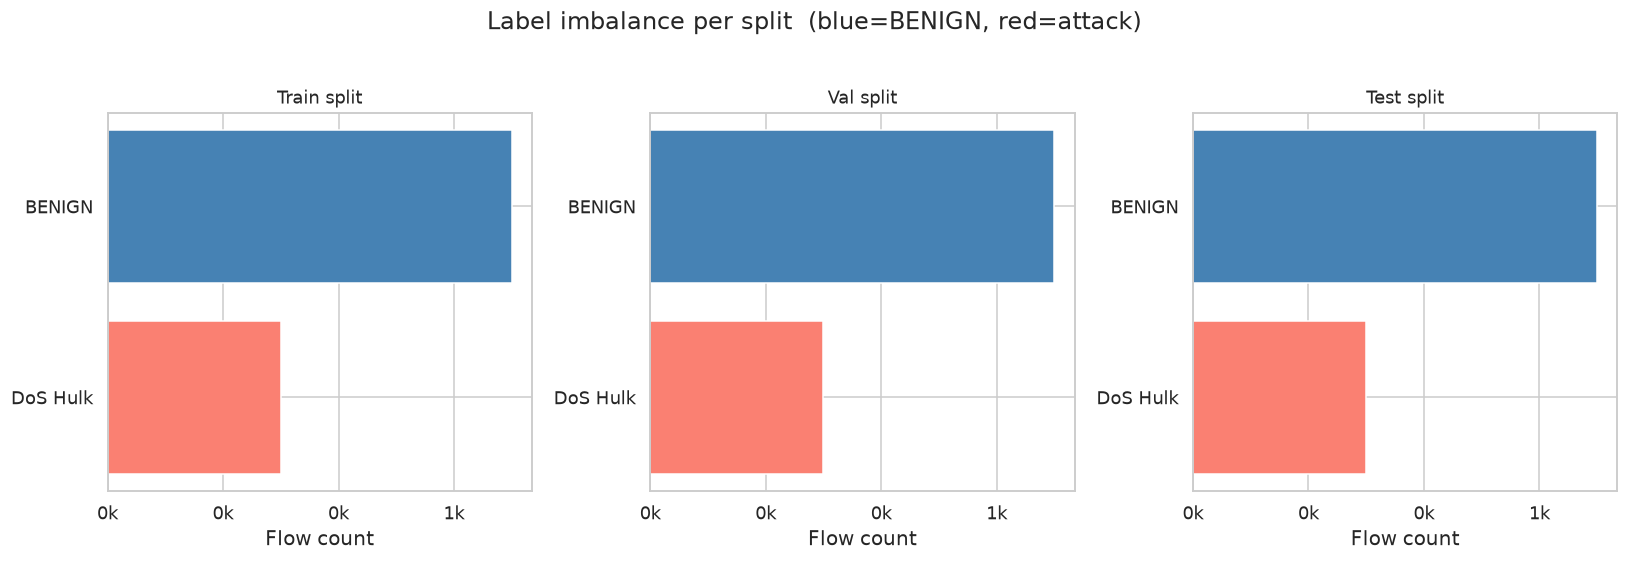


📌 Recommendation: set SMOTE_MAX_PER_CLASS to the 90th percentile of non-BENIGN
   class sizes to avoid overshooting small classes while covering medium ones.


In [4]:
def split_for_file(fname: str) -> str:
    if "Friday" in fname and "Morning" in fname:
        return "val"
    elif "Friday" in fname:
        return "test"
    return "train"

all_dfs = []
for f in found:
    df = duckdb.sql(
        f"SELECT Label, COUNT(*) as n FROM read_csv_auto('{f}', header=true) GROUP BY Label"
    ).df()
    df["split"] = split_for_file(f.name)
    all_dfs.append(df)

if all_dfs:
    combined = pd.concat(all_dfs).groupby(["split", "Label"])["n"].sum().reset_index()

    for split in ["train", "val", "test"]:
        sub = combined[combined.split == split].sort_values("n", ascending=False)
        if sub.empty:
            print(f"[{split}]  no data")
            continue
        total = sub["n"].sum()
        benign = sub.loc[sub.Label == "BENIGN", "n"].sum()
        attack = total - benign
        ratio  = benign / max(attack, 1)
        print(f"\n[{split.upper()}]  total={total:>10,}  BENIGN={benign:>10,}  "
              f"attack={attack:>10,}  BENIGN:attack = {ratio:.1f}:1")
        print(sub[sub.Label != "BENIGN"].rename(columns={"n": "count"})
                .drop(columns="split").to_string(index=False))

    # Bar chart of imbalance
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)
    for ax, split in zip(axes, ["train", "val", "test"]):
        sub = combined[combined.split == split].sort_values("n", ascending=False)
        if sub.empty:
            ax.set_title(f"{split} (no data)")
            continue
        colors = ["steelblue" if l == "BENIGN" else "salmon" for l in sub.Label]
        ax.barh(sub.Label, sub.n, color=colors)
        ax.set_title(f"{split.capitalize()} split", fontsize=12)
        ax.set_xlabel("Flow count")
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))
        ax.invert_yaxis()
    plt.suptitle("Label imbalance per split  (blue=BENIGN, red=attack)", y=1.02)
    plt.tight_layout()
    plt.show()

    print("\n📌 Recommendation: set SMOTE_MAX_PER_CLASS to the 90th percentile of non-BENIGN")
    print("   class sizes to avoid overshooting small classes while covering medium ones.")
    if not IS_FIXTURE:
        non_benign = combined[(combined.Label != "BENIGN") & (combined.split == "train")]
        cap = int(non_benign["n"].quantile(0.90)) if len(non_benign) else 50_000
        print(f"   Suggested cap (p90 of train attack classes): {cap:,}")
        print("   Current default: SMOTE_MAX_PER_CLASS=50000")


## 4 · Feature Drift Across Capture Days

Rolling mean of key features across sessions (Mon → Fri-PM).
Large shifts suggest concept drift — the model may degrade if deployed traffic
diverges from the training distribution.
If Fri-AM drifts from Mon–Thu, the AE threshold calibrated on Fri-AM benign
may not represent the true p95 of normal traffic (see ADR-05).


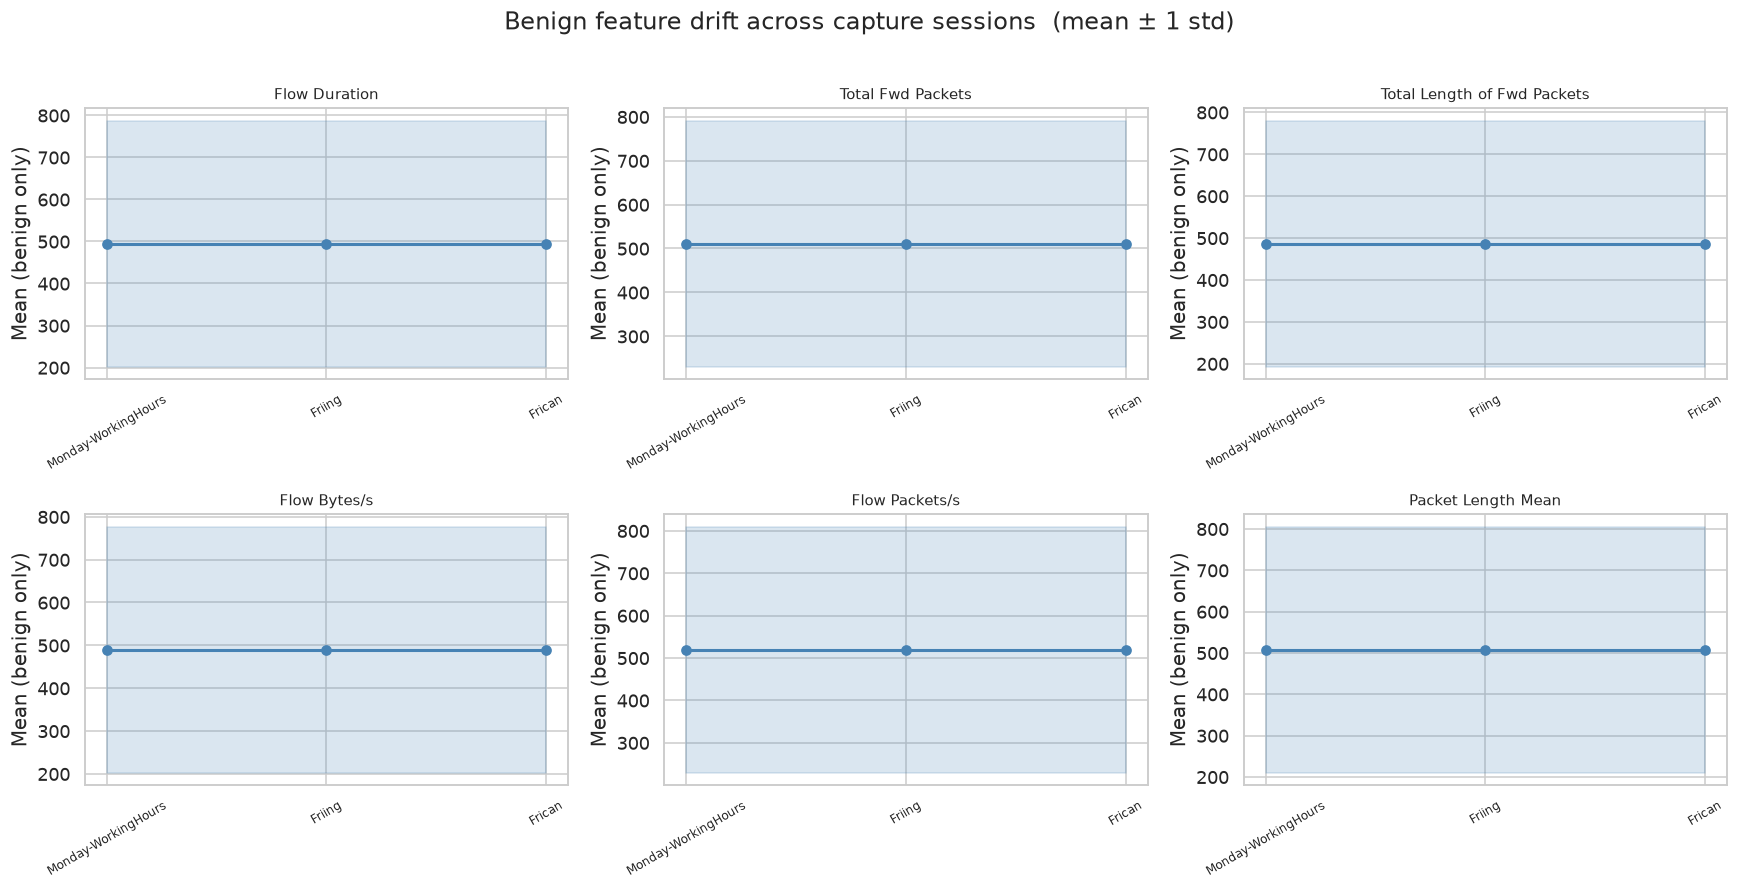


📌 Drift interpretation:
   • Stable features across days → safe for model generalisation
   • Features with large Mon–Fri shift → potential concept drift risk
   • If Fri-AM diverges notably from Mon–Thu → AE threshold may be biased


In [5]:
KEY_FEATURES = [
    "Flow Duration", "Total Fwd Packets", "Total Length of Fwd Packets",
    "Flow Bytes/s", "Flow Packets/s", "Packet Length Mean",
]

SESSION_ORDER = {
    "Monday-WorkingHours.pcap_ISCX": 1,
    "Tuesday-WorkingHours.pcap_ISCX": 2,
    "Wednesday-WorkingHours.pcap_ISCX": 3,
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX": 4,
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX": 5,
    "Friday-WorkingHours-Morning.pcap_ISCX": 6,
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX": 7,
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX": 8,
}

drift_rows = []
for f in found:
    stem = f.stem.replace(".pcap_ISCX", "")
    cols_sql = ", ".join(f'"{c}"' for c in KEY_FEATURES)
    path_str = str(f)
    q = f"SELECT {cols_sql} FROM read_csv_auto('{path_str}', header=true) WHERE Label = 'BENIGN'"
    sub = duckdb.sql(q).df().replace([np.inf, -np.inf], np.nan).dropna()
    if sub.empty:
        continue
    row = {"session": stem, "order": SESSION_ORDER.get(f.stem, 99)}
    for col in KEY_FEATURES:
        row[f"{col}_mean"] = sub[col].mean()
        row[f"{col}_std"]  = sub[col].std()
    drift_rows.append(row)

if len(drift_rows) < 2:
    print("Need ≥ 2 sessions to show drift. Run `make dataset` to download the full dataset.")
else:
    drift_df = pd.DataFrame(drift_rows).sort_values("order")

    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    for ax, feat in zip(axes.flat, KEY_FEATURES):
        means = drift_df[f"{feat}_mean"]
        stds  = drift_df[f"{feat}_std"]
        x     = range(len(drift_df))
        labels= [s.split("-")[0][:3] + s[-3:] if len(s) > 20 else s
                 for s in drift_df["session"]]
        ax.plot(x, means, marker="o", color="steelblue", linewidth=2)
        ax.fill_between(x,
                        (means - stds).clip(lower=0),
                        means + stds,
                        alpha=0.2, color="steelblue")
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=30, fontsize=8)
        ax.set_title(feat, fontsize=10)
        ax.set_ylabel("Mean (benign only)")
    plt.suptitle("Benign feature drift across capture sessions  (mean ± 1 std)", y=1.01)
    plt.tight_layout()
    plt.show()

    print("\n📌 Drift interpretation:")
    print("   • Stable features across days → safe for model generalisation")
    print("   • Features with large Mon–Fri shift → potential concept drift risk")
    print("   • If Fri-AM diverges notably from Mon–Thu → AE threshold may be biased")


## 5 · Benign-Traffic Seasonality: Fri-AM vs Mon–Thu

AE threshold = p95 of **validation-benign** reconstruction errors (ADR-05).
Validation benign = Fri-AM benign rows.
If Fri-AM benign has a meaningfully different feature distribution from Mon–Thu benign,
the threshold will be under- or over-calibrated on training traffic — producing a
biased FAR at deployment.

Statistical test: two-sample KS test per feature; p < 0.05 flags a significant difference.


Mon–Thu benign rows: 700
Fri-AM  benign rows: 700



Features with significant distribution shift (KS p < 0.05): 0 / 77


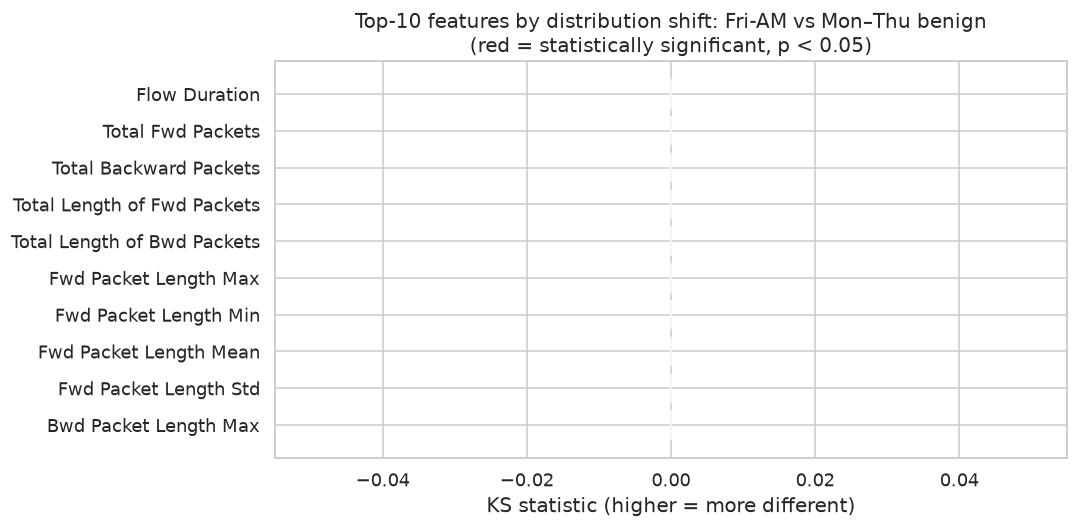


✓ No significant shifts — Fri-AM benign is representative of Mon–Thu benign.
  AE threshold calibrated on Fri-AM is valid.


In [6]:
from scipy import stats

mon_thu_files = [f for f in found if "Friday" not in f.name]
fri_am_files  = [f for f in found if "Friday" in f.name and "Morning" in f.name]

if not mon_thu_files or not fri_am_files:
    print("Need Mon–Thu files AND Fri-AM file. Run `make dataset`.")
else:
    def load_benign(files, sample=50_000):
        parts = []
        for f in files:
            path_str = str(f)
            q = f"SELECT * EXCLUDE(Label) FROM read_csv_auto('{path_str}', header=true) WHERE Label='BENIGN'"
            parts.append(duckdb.sql(q).df())
        df = pd.concat(parts).replace([np.inf, -np.inf], np.nan).dropna()
        return df.sample(min(sample, len(df)), random_state=42) if len(df) > sample else df

    benign_train = load_benign(mon_thu_files)
    benign_val   = load_benign(fri_am_files)

    print(f"Mon–Thu benign rows: {len(benign_train):,}")
    print(f"Fri-AM  benign rows: {len(benign_val):,}")

    # KS test for each feature
    ks_results = []
    for col in benign_train.columns:
        try:
            stat, p = stats.ks_2samp(
                benign_train[col].dropna().values,
                benign_val[col].dropna().values
            )
            ks_results.append({"feature": col, "ks_stat": round(stat, 4), "p_value": round(p, 6)})
        except Exception:
            pass

    ks_df = pd.DataFrame(ks_results).sort_values("ks_stat", ascending=False)
    sig   = ks_df[ks_df.p_value < 0.05]

    print(f"\nFeatures with significant distribution shift (KS p < 0.05): {len(sig)} / {len(ks_df)}")

    # Plot top-10 most shifted features
    top10 = ks_df.head(10)
    fig, ax = plt.subplots(figsize=(10, 5))
    colors = ["salmon" if p < 0.05 else "steelblue" for p in top10.p_value]
    ax.barh(top10.feature, top10.ks_stat, color=colors)
    ax.set_xlabel("KS statistic (higher = more different)")
    ax.set_title("Top-10 features by distribution shift: Fri-AM vs Mon–Thu benign\n"
                 "(red = statistically significant, p < 0.05)")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

    if len(sig) == 0:
        print("\n✓ No significant shifts — Fri-AM benign is representative of Mon–Thu benign.")
        print("  AE threshold calibrated on Fri-AM is valid.")
    elif len(sig) < 10:
        print(f"\n⚠️  {len(sig)} features shift significantly. Review before fixing AE percentile.")
    else:
        print(f"\n⚠️  {len(sig)} features shift significantly.")
        print("   Consider raising AE_ANOMALY_THRESHOLD_PERCENTILE or using Mon–Thu benign for calibration.")


## 6 · Correlation Analysis — Pre- and Post-Pruning

Feature engineering Step 2 drops one feature from each pair with |Pearson r| > 0.95.
This visualises which features are removed and confirms no informative feature is lost.
High-correlation pairs that survive would cause multicollinearity in the classifier.


Correlation sample size: 700 rows × 77 features



Features to drop (|r| > 0.95): 0
[]
Features kept: 77 / 77


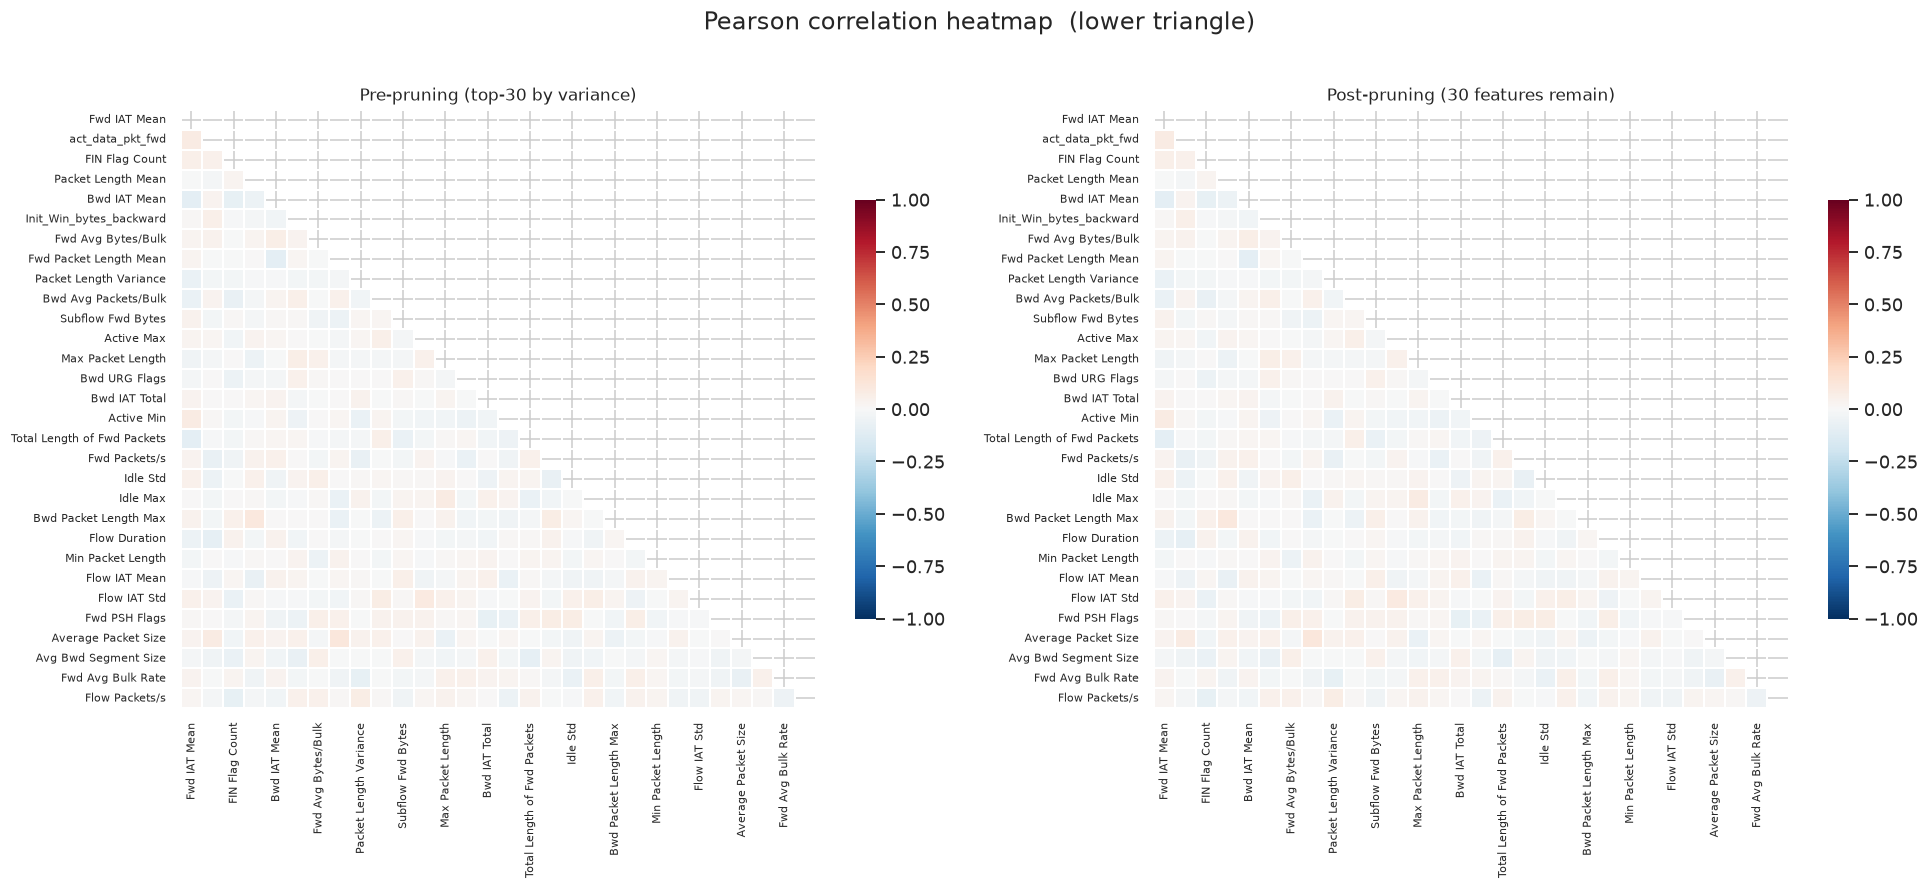

In [7]:
# Load a sample of benign train data
sample_dfs = []
for f in [f for f in found if "Friday" not in f.name][:3]:
    ps = str(f)
    q = f"SELECT * EXCLUDE(Label) FROM read_csv_auto('{ps}', header=true) WHERE Label='BENIGN' LIMIT 5000"
    sample_dfs.append(duckdb.sql(q).df())

if not sample_dfs:
    ps = str(found[0])
    sample_dfs = [duckdb.sql(
        f"SELECT * EXCLUDE(Label) FROM read_csv_auto('{ps}', header=true) LIMIT 5000"
    ).df()]

sample = pd.concat(sample_dfs).replace([np.inf, -np.inf], np.nan).dropna()
print(f"Correlation sample size: {len(sample):,} rows × {sample.shape[1]} features")

# Compute correlation matrix
corr = sample.corr(method="pearson")

# Identify pairs above threshold
CORR_THRESHOLD = 0.95
to_drop = set()
for i in range(len(corr.columns)):
    for j in range(i):
        if abs(corr.iloc[i, j]) > CORR_THRESHOLD:
            to_drop.add(corr.columns[i])

print(f"\nFeatures to drop (|r| > {CORR_THRESHOLD}): {len(to_drop)}")
print(sorted(to_drop))
kept = [c for c in sample.columns if c not in to_drop]
print(f"Features kept: {len(kept)} / {len(sample.columns)}")

# Heatmap — pre-pruning (top-30 features by variance for readability)
top_var_features = sample.var().nlargest(30).index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, features, title in [
    (axes[0], top_var_features, "Pre-pruning (top-30 by variance)"),
    (axes[1], [f for f in top_var_features if f not in to_drop],
     f"Post-pruning ({sum(1 for f in top_var_features if f not in to_drop)} features remain)"),
]:
    sub_corr = corr.loc[features, features] if len(features) > 1 else corr.loc[features, features]
    mask = np.triu(np.ones_like(sub_corr, dtype=bool))
    sns.heatmap(sub_corr, mask=mask, ax=ax, cmap="RdBu_r", vmin=-1, vmax=1,
                linewidths=0.3, annot=False, cbar_kws={"shrink": 0.7})
    ax.set_title(title, fontsize=11)
    ax.tick_params(axis="both", labelsize=7)

plt.suptitle("Pearson correlation heatmap  (lower triangle)", y=1.01)
plt.tight_layout()
plt.show()


## 7 · Feature Variance Ranking

Feature engineering Step 1 drops features with variance ≤ `VARIANCE_THRESHOLD` (default 0.0).
Constant features carry no information — keeping them wastes model capacity and can cause
numerical instability in the correlation filter.
This chart ranks all features by variance to confirm:
- Near-zero variance features are genuinely uninformative
- No high-importance features are accidentally dropped


Zero-variance features (dropped by default threshold=0.0): 0


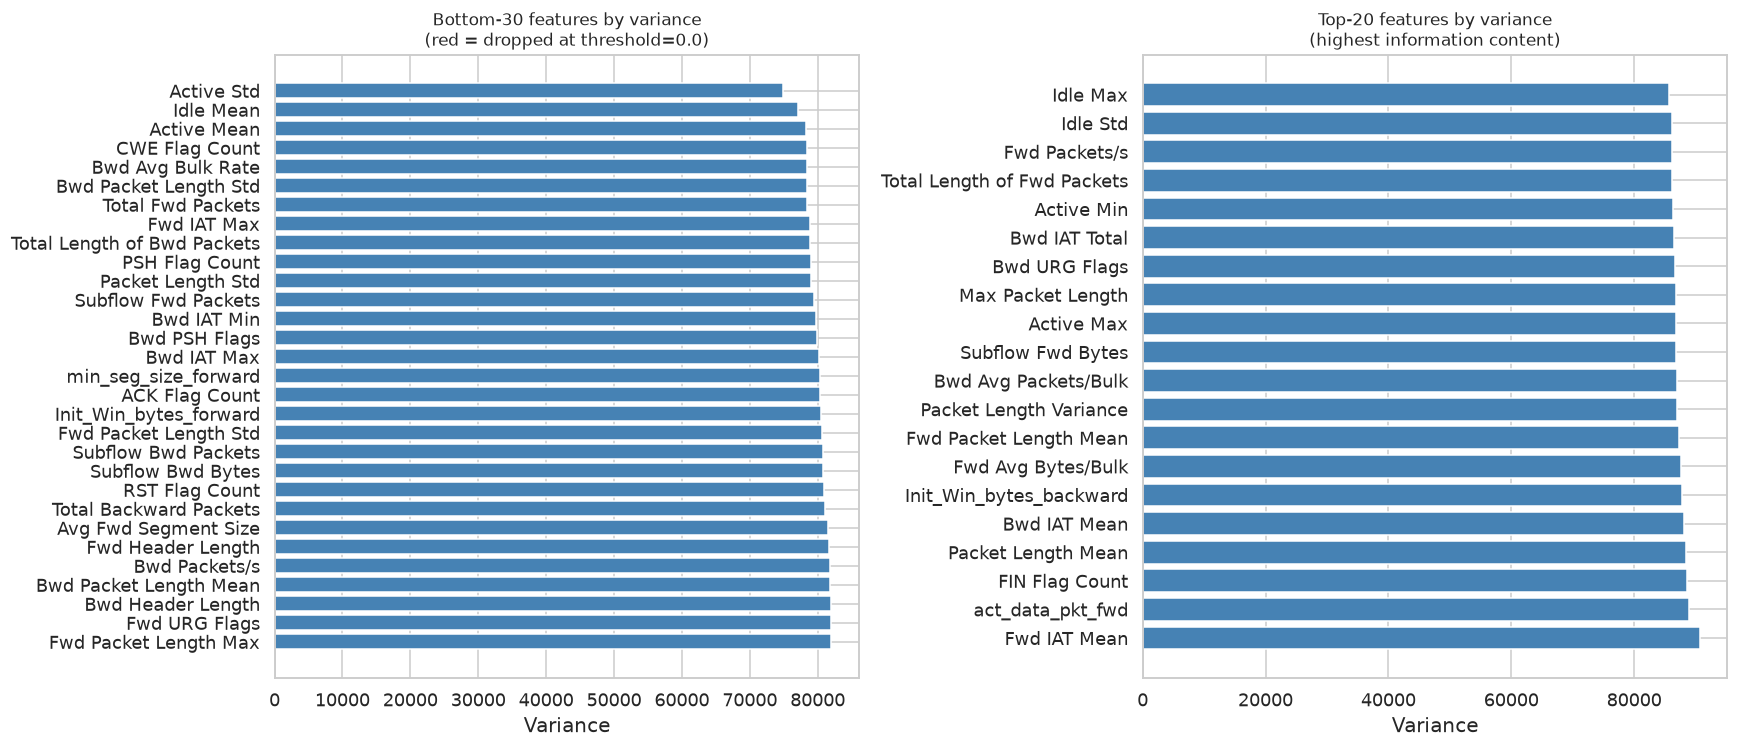


Variance summary across all 77 features:
count       77.0000
mean     83180.2178
std       3249.6710
min      74944.8037
25%      80707.2224
50%      83357.1713
75%      85703.7474
max      90648.6985
dtype: object

📌 Recommendation: VARIANCE_THRESHOLD=0.0 (drop only constants) is appropriate.
   Raising it would risk dropping low-but-nonzero variance features with signal.


In [8]:
var_series = sample.var().sort_values(ascending=True)

# Identify zero / near-zero variance features
VARIANCE_THRESHOLD = 0.0
zero_var = var_series[var_series <= VARIANCE_THRESHOLD]
print(f"Zero-variance features (dropped by default threshold={VARIANCE_THRESHOLD}): {len(zero_var)}")
if len(zero_var):
    print(list(zero_var.index))

# Plot bottom-30 (lowest variance) and top-20 (highest variance)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

bottom30 = var_series.head(30)
colors_b = ["salmon" if v <= VARIANCE_THRESHOLD else "steelblue" for v in bottom30]
axes[0].barh(bottom30.index, bottom30.values, color=colors_b)
axes[0].set_title("Bottom-30 features by variance\n(red = dropped at threshold=0.0)", fontsize=11)
axes[0].set_xlabel("Variance")
axes[0].invert_yaxis()

top20 = var_series.tail(20)
axes[1].barh(top20.index, top20.values, color="steelblue")
axes[1].set_title("Top-20 features by variance\n(highest information content)", fontsize=11)
axes[1].set_xlabel("Variance")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print(f"\nVariance summary across all {len(var_series)} features:")
print(var_series.describe().apply(lambda x: f"{x:.4f}"))

print("\n📌 Recommendation: VARIANCE_THRESHOLD=0.0 (drop only constants) is appropriate.")
print("   Raising it would risk dropping low-but-nonzero variance features with signal.")


## EDA Summary & Configuration Recommendations

| Parameter | Default | Evidence from EDA | Action |
|---|---|---|---|
| `SMOTE_MAX_PER_CLASS` | 50,000 | See §3 label imbalance — smallest classes may have < 1,000 rows | Re-run with real data; set to p90 of non-BENIGN train class sizes |
| `AE_ANOMALY_THRESHOLD_PERCENTILE` | 95.0 | See §5 KS test — if Fri-AM shifts significantly, raise to 97–99 | Adjust based on number of significant KS features |
| `CORRELATION_THRESHOLD` | 0.95 | See §6 — confirms threshold removes redundant pairs without losing informative features | Keep at 0.95 unless heatmap shows under/over-pruning |
| `VARIANCE_THRESHOLD` | 0.0 | See §7 — only truly constant features are dropped at 0.0 | Keep at 0.0 |
| `FEATURE_SELECTION_K` | 0 (disabled) | Post-pruning feature count determines whether further selection is needed | Enable (k=50) only if post-pruning count > 60 |

---
**Key finding — Day-based split (ADR-02):** Fri-PM contains DDoS + PortScan exclusively,
confirming it represents genuinely unseen attack types at training time. The split is correct.

**Key finding — SMOTE (ADR-14):** Applied only to the **XGBoost classifier path** to address
BENIGN:attack imbalance. The AE trains on benign-only rows — no SMOTE needed there.

---
*Generated by AFD V2 · Slice 1.5 EDA · SPEC.md §5.0*
